# Build EMOPAIR Dataset

Using the results from `validate_LLMs.ipynb`, we can now build the EMOPAIR dataset.

Based on the Alt-Test results, we will use the following LLMs as annotators:
- Valence: No LLMs passed the Alt-Test for valence, so we will not use any LLMs as annotators for this dimension.
- Arousal: GPT-5.1
- Dominance: GPT-5-nano

For Valence, we will use the prior EMOBANK data. 

In [1]:
import os
import pandas as pd 
import pairadigm as pdm

import dotenv

dotenv.load_dotenv(dotenv_path='/Users/mlchrzan/Library/CloudStorage/OneDrive-Personal/Professional/Data Science/Maryland/bechmark analysis pipeline/benchmark-analysis/.env')

/Users/mlchrzan/opt/anaconda3/envs/emopair/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

## Prep

In [2]:
# Load EMOBANK data to get the original text data
emobank = pd.read_csv('Data/emobank.csv')
emobank

,id,split,V,A,D,text
0,110CYL068_1036_1079,train,3.00,3.00,3.20,"Remember what she said in my last letter? """
1,110CYL068_1079_1110,test,2.80,3.10,2.80,If I wasn't working here.
2,110CYL068_1127_1130,train,3.00,3.00,3.00,".."""
3,110CYL068_1137_1188,train,3.44,3.00,3.22,Goodwill helps people get off of public assist...
4,110CYL068_1189_1328,train,3.55,3.27,3.46,Sherry learned through our Future Works class ...
...,...,...,...,...,...,...
10057,wwf12_4531_4624,train,3.00,3.50,3.00,Please let it be a constant reminder of all yo...
10058,wwf12_501_591,train,3.80,3.40,3.60,That’s why I want to extend my appreciation fo...
10059,wwf12_592_691,train,3.00,3.00,3.10,And why I’m writing you today to ask you to re...
10060,wwf12_702_921,train,3.33,3.44,3.44,"In fact, I want to urge you to strengthen your..."


In [3]:
# Load CGCOT Prompts
with open('Data/cgcot_prompts/valence.txt', 'r') as file:
    val_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/arousal.txt', 'r') as file:
    aro_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/dominance.txt', 'r') as file:
    dom_prompts = file.read().splitlines()

## Build pairadigms

In [4]:
emopair_aro = pdm.Pairadigm(
    data = emobank, 
    item_id_name='id', 
    text_name='text',
    cgcot_prompts=aro_prompts,
    model_name='gpt-5.1', 
    api_key=os.getenv('OPENAI_API_KEY'),
    base_url="https://us.api.openai.com/v1", 
    target_concept='arousal'
)

emopair_dom = pdm.Pairadigm(
    data = emobank, 
    item_id_name='id', 
    text_name='text',
    cgcot_prompts=dom_prompts,
    model_name='gpt-5-nano', 
    api_key=os.getenv('OPENAI_API_KEY'),
    target_concept='dominance'
)

In [6]:
emopair_aro.generate_breakdowns()


Generating breakdowns for 10062 items using: gpt-5.1
[10062/10062] 100.0% complete
Completed: 10062/10062 items

Breakdowns added to [object name].data with column name(s): CGCoT_Breakdown


In [8]:
emopair_aro.generate_pairings(breakdowns=True)

Pairwise DataFrame with breakdowns created and stored in self.pairwise_df


,item1,item2,breakdown1,breakdown2
0,Homosexuality_12358_12505,Homosexuality_12457_12505,Original Text: Dobbens reasoned that most pare...,Original Text: “They’re not like ‘My child’s g...
1,The_Black_Willow_11483_11570,lessig_blog-carbon_5617_5700,Original Text: You need not pander to what you...,Original Text: I just finished insulating my h...
2,cable_spool_fort_8413_8465,cable_spool_fort_8516_8674,Original Text: Chad stepped back away from Tuc...,"Original Text: ""I thought he might stab you."" ..."
3,Nathans_Bylichka_57176_57235,defenders5_1090_1102,Original Text: Then my eyes opened and Amy han...,Original Text: “can’t-miss”\nPrompt 1 response...
4,Nathans_Bylichka_12685_12703,anth_essay_4_7685_7776,Original Text: “Who’s the freak?”\nPrompt 1 re...,Original Text: It often stands in conflict wit...
...,...,...,...,...
58216,SemEval_602,lw1_2561_2592,Original Text: A Mistrial for Lieut. Watada\nP...,Original Text: He was what this was all about....
58217,Ohio_Steel_14047_14126,vampires_1126_1179,Original Text: People became excited and waite...,Original Text: Ninja Warrior is one of the mos...
58218,SemEval_871,hotel-california_29819_29868,Original Text: Human error caused Helios crash...,Original Text: Had anyone on the ship ever fal...
58219,Ant_Robot_339_506,Nathans_Bylichka_14614_14634,"Original Text: Unfortunately, as of yet, no ro...",Original Text: “What do you think?”\nPrompt 1 ...


In [ ]:
emopair_aro.generate_pairwise_annotations(allow_ties=True)
# run time: 140 minutes

[default] Completed 50/58221 comparisons
[default] Completed 100/58221 comparisons
[default] Completed 150/58221 comparisons
[default] Completed 200/58221 comparisons
[default] Completed 250/58221 comparisons
[default] Completed 300/58221 comparisons
[default] Completed 350/58221 comparisons
[default] Completed 400/58221 comparisons
[default] Completed 450/58221 comparisons
[default] Completed 500/58221 comparisons
[default] Completed 550/58221 comparisons
[default] Completed 600/58221 comparisons
[default] Completed 650/58221 comparisons
[default] Completed 700/58221 comparisons
[default] Completed 750/58221 comparisons
[default] Completed 800/58221 comparisons
[default] Completed 850/58221 comparisons
[default] Completed 900/58221 comparisons
[default] Completed 950/58221 comparisons
[default] Completed 1000/58221 comparisons
[default] Completed 1050/58221 comparisons
[default] Completed 1100/58221 comparisons
[default] Completed 1150/58221 comparisons
[default] Completed 1200/58221 

,item1,item2,breakdown1,breakdown2,decision,justification
0,Homosexuality_12358_12505,Homosexuality_12457_12505,Original Text: Dobbens reasoned that most pare...,Original Text: “They’re not like ‘My child’s g...,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...
1,The_Black_Willow_11483_11570,lessig_blog-carbon_5617_5700,Original Text: You need not pander to what you...,Original Text: I just finished insulating my h...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
2,cable_spool_fort_8413_8465,cable_spool_fort_8516_8674,Original Text: Chad stepped back away from Tuc...,"Original Text: ""I thought he might stab you."" ...",Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...
3,Nathans_Bylichka_57176_57235,defenders5_1090_1102,Original Text: Then my eyes opened and Amy han...,Original Text: “can’t-miss”\nPrompt 1 response...,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...
4,Nathans_Bylichka_12685_12703,anth_essay_4_7685_7776,Original Text: “Who’s the freak?”\nPrompt 1 re...,Original Text: It often stands in conflict wit...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
...,...,...,...,...,...,...
58216,SemEval_602,lw1_2561_2592,Original Text: A Mistrial for Lieut. Watada\nP...,Original Text: He was what this was all about....,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...
58217,Ohio_Steel_14047_14126,vampires_1126_1179,Original Text: People became excited and waite...,Original Text: Ninja Warrior is one of the mos...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
58218,SemEval_871,hotel-california_29819_29868,Original Text: Human error caused Helios crash...,Original Text: Had anyone on the ship ever fal...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
58219,Ant_Robot_339_506,Nathans_Bylichka_14614_14634,"Original Text: Unfortunately, as of yet, no ro...",Original Text: “What do you think?”\nPrompt 1 ...,Tie,FINAL ANSWER: Tie \nJUSTIFICATION: Both descr...


In [ ]:
emopair_aro.score_items(normalization_scale='negative-one-to-one', 
                        use_davidson=True)
# run time: 85 minutes

/Users/mlchrzan/opt/anaconda3/envs/emopair/lib/python3.12/site-packages/pairadigm/core.py:3201: RuntimeWarning: invalid value encountered in scalar divide
  denominator += (wins[i, j] + wins[j, i]) / (scores[i] + scores[j])


Davidson model converged in 80 iterations
[default] Davidson model fitted with 58221 comparisons
[default] Including 18547 tie decisions
[default] Mean arousal score: -0.643
[default] Std arousal score: 0.271
Score range: -1.000 to 1.000
25th percentile: -0.828
50th percentile (median): -0.729
75th percentile: -0.547

Highest scoring item on arousal (score: 1.000):
The report charged that Panama's Manuel Noriega is not only in league with the drug traffickers but also is bullying the press as never before.

Lowest scoring item on arousal (score: -1.000):
She took a sip of her drink, plain water because, she had explained earlier, she had never liked the taste of alcohol, then fixed her gaze on me.
mean: -0.643
median: -0.729
std: 0.271
min: -1.000
max: 1.000
count: 10062.000


,id,split,V,A,D,text,CGCoT_Breakdown,Davidson_Score
0,110CYL068_1036_1079,train,3.00,3.00,3.20,"Remember what she said in my last letter? """,Original Text: Remember what she said in my la...,-0.735353
1,110CYL068_1079_1110,test,2.80,3.10,2.80,If I wasn't working here.,Original Text: If I wasn't working here.\nProm...,-0.805996
2,110CYL068_1127_1130,train,3.00,3.00,3.00,"..""","Original Text: ..""\nPrompt 1 response: You onl...",-0.760068
3,110CYL068_1137_1188,train,3.44,3.00,3.22,Goodwill helps people get off of public assist...,Original Text: Goodwill helps people get off o...,-0.883139
4,110CYL068_1189_1328,train,3.55,3.27,3.46,Sherry learned through our Future Works class ...,Original Text: Sherry learned through our Futu...,-0.766052
...,...,...,...,...,...,...,...,...
10057,wwf12_4531_4624,train,3.00,3.50,3.00,Please let it be a constant reminder of all yo...,Original Text: Please let it be a constant rem...,-0.096232
10058,wwf12_501_591,train,3.80,3.40,3.60,That’s why I want to extend my appreciation fo...,Original Text: That’s why I want to extend my ...,-0.881812
10059,wwf12_592_691,train,3.00,3.00,3.10,And why I’m writing you today to ask you to re...,Original Text: And why I’m writing you today t...,-0.514307
10060,wwf12_702_921,train,3.33,3.44,3.44,"In fact, I want to urge you to strengthen your...","Original Text: In fact, I want to urge you to ...",-0.336570


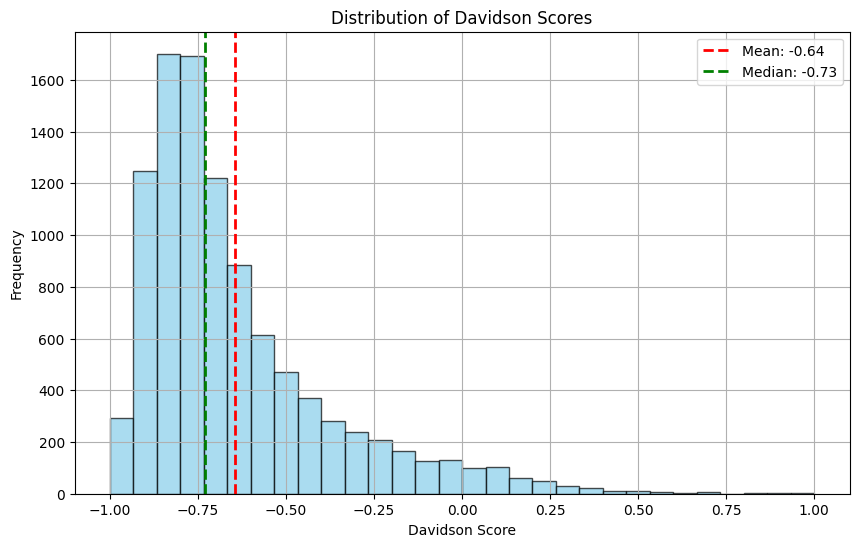

In [20]:
emopair_aro.scored_df

import matplotlib.pyplot as plt

# Plot the distribution
plt.figure(figsize=(10, 6))
emopair_aro.scored_df['Davidson_Score'].hist(bins=30, alpha=0.7, color='skyblue', edgecolor='black')

# Calculate mean and median
mean_score = emopair_aro.scored_df['Davidson_Score'].mean()
median_score = emopair_aro.scored_df['Davidson_Score'].median()

# Add vertical lines for mean and median
plt.axvline(mean_score, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_score:.2f}')
plt.axvline(median_score, color='green', linestyle='dashed', linewidth=2, label=f'Median: {median_score:.2f}')

# Add labels and title
plt.title('Distribution of Davidson Scores')
plt.xlabel('Davidson Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [25]:
emopair_aro.pairwise_df['decision'].value_counts()

decision
Text2    20136
Text1    19538
Tie      18547
Name: count, dtype: int64

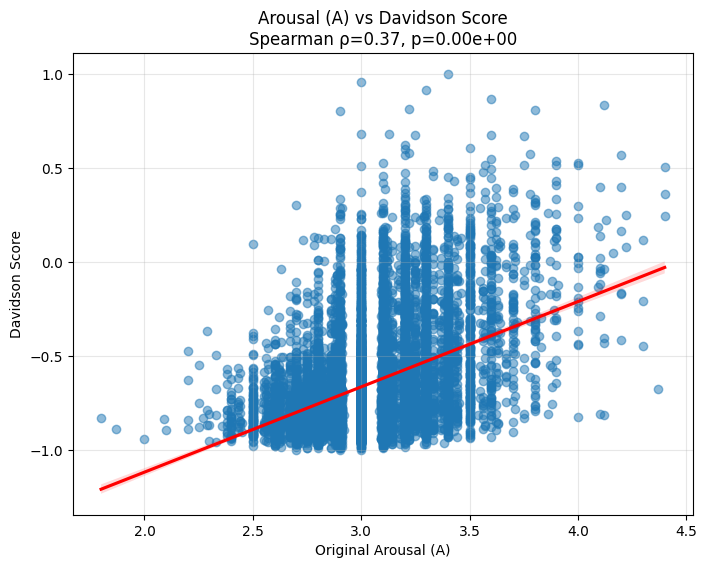

In [31]:
import seaborn as sns
from scipy import stats

# Calculate correlation statistics
r, p = stats.spearmanr(emopair_aro.scored_df['A'], emopair_aro.scored_df['Davidson_Score'])

# Create the plot
plt.figure(figsize=(8, 6))
sns.regplot(data=emopair_aro.scored_df, x='A', y='Davidson_Score', 
            scatter_kws={'alpha':0.5}, line_kws={'color': 'red'})

# Add labels and title with stats
plt.title(f'Arousal (A) vs Davidson Score\nSpearman ρ={r:.2f}, p={p:.2e}')
plt.xlabel('Original Arousal (A)')
plt.ylabel('Davidson Score')
plt.grid(True, alpha=0.3)
plt.show()

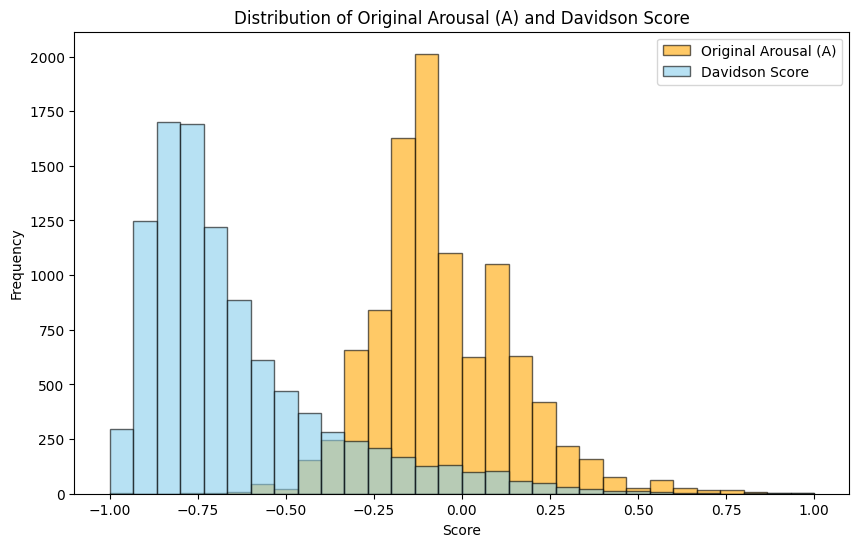

In [30]:
# Rescale 'A' from original (likely 1-5) to -1 to 1
A_min, A_max = emopair_aro.scored_df['A'].min(), emopair_aro.scored_df['A'].max()
emopair_aro.scored_df['A_rescaled'] = 2 * (emopair_aro.scored_df['A'] - A_min) / (A_max - A_min) - 1

plt.figure(figsize=(10, 6))

# Plot histogram for 'A'
plt.hist(emopair_aro.scored_df['A_rescaled'], bins=30, alpha=0.6, color='orange', label='Original Arousal (A)', edgecolor='black')

# Plot histogram for 'Davidson_Score'
plt.hist(emopair_aro.scored_df['Davidson_Score'], bins=30, alpha=0.6, color='skyblue', label='Davidson Score', edgecolor='black')

plt.title('Distribution of Original Arousal (A) and Davidson Score')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [21]:
emopair_aro.save('Results/pairadigms/emopair_aro')

Pairadigm object saved successfully to: Results/pairadigms/emopair_aro.pkl


In [27]:
emopair_aro.scored_df.to_csv('Results/emopair_aro_scores.csv', index=False)

# Untied Version

After interrogating the highly skewed distribution and high prevalence of ties in the pairwise annotations, we will build an untied version of the pairadigms by not allowing ties during the pairwise annotation generation step.

From our work in `validate_LLMs.ipynb`, we found that the following LLMs were the best performers without ties allowed:
- Valence: N/A
- Arousal: GPT-5.1
- Dominance: Claude-Sonnet 4.5

Note, everything in the Prep section above needs to be run first.

In [34]:
emopair_aro_untied = pdm.Pairadigm(
    data = emopair_aro.data, 
    item_id_name='id', 
    text_name='text',
    prior_breakdown_cols=['CGCOT_Breakdown'],
    cgcot_prompts=aro_prompts,
    model_name='gpt-5.1', 
    api_key=os.getenv('OPENAI_API_KEY'),
    base_url="https://us.api.openai.com/v1", 
    target_concept='arousal'
)


In [37]:
emopair_aro_untied.generate_pairings(breakdowns=True)

Pairwise DataFrame with breakdowns created and stored in self.pairwise_df


,item1,item2,breakdown1,breakdown2
0,Homosexuality_12358_12505,Homosexuality_12457_12505,Original Text: Dobbens reasoned that most pare...,Original Text: “They’re not like ‘My child’s g...
1,The_Black_Willow_11483_11570,lessig_blog-carbon_5617_5700,Original Text: You need not pander to what you...,Original Text: I just finished insulating my h...
2,cable_spool_fort_8413_8465,cable_spool_fort_8516_8674,Original Text: Chad stepped back away from Tuc...,"Original Text: ""I thought he might stab you."" ..."
3,Nathans_Bylichka_57176_57235,defenders5_1090_1102,Original Text: Then my eyes opened and Amy han...,Original Text: “can’t-miss”\nPrompt 1 response...
4,Nathans_Bylichka_12685_12703,anth_essay_4_7685_7776,Original Text: “Who’s the freak?”\nPrompt 1 re...,Original Text: It often stands in conflict wit...
...,...,...,...,...
58216,SemEval_602,lw1_2561_2592,Original Text: A Mistrial for Lieut. Watada\nP...,Original Text: He was what this was all about....
58217,Ohio_Steel_14047_14126,vampires_1126_1179,Original Text: People became excited and waite...,Original Text: Ninja Warrior is one of the mos...
58218,SemEval_871,hotel-california_29819_29868,Original Text: Human error caused Helios crash...,Original Text: Had anyone on the ship ever fal...
58219,Ant_Robot_339_506,Nathans_Bylichka_14614_14634,"Original Text: Unfortunately, as of yet, no ro...",Original Text: “What do you think?”\nPrompt 1 ...


In [39]:
emopair_aro_untied.generate_pairwise_annotations()

[default] Completed 50/58221 comparisons
[default] Completed 100/58221 comparisons
[default] Completed 150/58221 comparisons
[default] Completed 200/58221 comparisons
[default] Completed 250/58221 comparisons
[default] Completed 300/58221 comparisons
[default] Completed 350/58221 comparisons
[default] Completed 400/58221 comparisons
[default] Completed 450/58221 comparisons
[default] Completed 500/58221 comparisons
[default] Completed 550/58221 comparisons
[default] Completed 600/58221 comparisons
[default] Completed 650/58221 comparisons
[default] Completed 700/58221 comparisons
[default] Completed 750/58221 comparisons
[default] Completed 800/58221 comparisons
[default] Completed 850/58221 comparisons
[default] Completed 900/58221 comparisons
[default] Completed 950/58221 comparisons
[default] Completed 1000/58221 comparisons
[default] Completed 1050/58221 comparisons
[default] Completed 1100/58221 comparisons
[default] Completed 1150/58221 comparisons
[default] Completed 1200/58221 

,item1,item2,breakdown1,breakdown2,decision,justification
0,Homosexuality_12358_12505,Homosexuality_12457_12505,Original Text: Dobbens reasoned that most pare...,Original Text: “They’re not like ‘My child’s g...,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...
1,The_Black_Willow_11483_11570,lessig_blog-carbon_5617_5700,Original Text: You need not pander to what you...,Original Text: I just finished insulating my h...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
2,cable_spool_fort_8413_8465,cable_spool_fort_8516_8674,Original Text: Chad stepped back away from Tuc...,"Original Text: ""I thought he might stab you."" ...",Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...
3,Nathans_Bylichka_57176_57235,defenders5_1090_1102,Original Text: Then my eyes opened and Amy han...,Original Text: “can’t-miss”\nPrompt 1 response...,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...
4,Nathans_Bylichka_12685_12703,anth_essay_4_7685_7776,Original Text: “Who’s the freak?”\nPrompt 1 re...,Original Text: It often stands in conflict wit...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
...,...,...,...,...,...,...
58216,SemEval_602,lw1_2561_2592,Original Text: A Mistrial for Lieut. Watada\nP...,Original Text: He was what this was all about....,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...
58217,Ohio_Steel_14047_14126,vampires_1126_1179,Original Text: People became excited and waite...,Original Text: Ninja Warrior is one of the mos...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
58218,SemEval_871,hotel-california_29819_29868,Original Text: Human error caused Helios crash...,Original Text: Had anyone on the ship ever fal...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
58219,Ant_Robot_339_506,Nathans_Bylichka_14614_14634,"Original Text: Unfortunately, as of yet, no ro...",Original Text: “What do you think?”\nPrompt 1 ...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...


In [43]:
emopair_aro_untied.score_items(normalization_scale='negative-one-to-one')

[default] Bradley-Terry model fitted with 58221 comparisons
[default] Mean arousal score: 0.004
[default] Std arousal score: 0.371
Score range: -1.000 to 1.000
25th percentile: -0.312
50th percentile (median): 0.005
75th percentile: 0.321

Highest scoring item on arousal (score: 1.000):
Apparently the drug use, sexual excess, and weird UCI experiences haven't softened your brain yet.

Lowest scoring item on arousal (score: -1.000):
"wholesale"
mean: 0.004
median: 0.005
std: 0.371
min: -1.000
max: 1.000
count: 10062.000


,id,split,V,A,D,text,CGCoT_Breakdown,Bradley_Terry_Score
0,110CYL068_1036_1079,train,3.00,3.00,3.20,"Remember what she said in my last letter? """,Original Text: Remember what she said in my la...,0.214964
1,110CYL068_1079_1110,test,2.80,3.10,2.80,If I wasn't working here.,Original Text: If I wasn't working here.\nProm...,-0.206263
2,110CYL068_1127_1130,train,3.00,3.00,3.00,"..""","Original Text: ..""\nPrompt 1 response: You onl...",-0.524366
3,110CYL068_1137_1188,train,3.44,3.00,3.22,Goodwill helps people get off of public assist...,Original Text: Goodwill helps people get off o...,-0.417513
4,110CYL068_1189_1328,train,3.55,3.27,3.46,Sherry learned through our Future Works class ...,Original Text: Sherry learned through our Futu...,0.110363
...,...,...,...,...,...,...,...,...
10057,wwf12_4531_4624,train,3.00,3.50,3.00,Please let it be a constant reminder of all yo...,Original Text: Please let it be a constant rem...,0.477870
10058,wwf12_501_591,train,3.80,3.40,3.60,That’s why I want to extend my appreciation fo...,Original Text: That’s why I want to extend my ...,-0.416795
10059,wwf12_592_691,train,3.00,3.00,3.10,And why I’m writing you today to ask you to re...,Original Text: And why I’m writing you today t...,0.372718
10060,wwf12_702_921,train,3.33,3.44,3.44,"In fact, I want to urge you to strengthen your...","Original Text: In fact, I want to urge you to ...",0.582596


In [ ]:
# Save Local
emopair_aro_untied.save('Results/pairadigms/emopair_aro_untied')
emopair_aro_untied.pairwise_df.to_csv('Results/emopair_aro_untied_pairwise_annotations.csv', index=False)
emopair_aro_untied.scored_df.to_csv('Results/emopair_aro_untied_scores.csv', index=False)

# Save to Box
emopair_aro_untied.save('/Users/mlchrzan/Library/CloudStorage/Box-Box/emopair_aro_untied')
emopair_aro_untied.pairwise_df.to_csv('/Users/mlchrzan/Library/CloudStorage/Box-Box/emopair_aro_untied_pairwise_annotations.csv', index=False)
emopair_aro_untied.scored_df.to_csv('/Users/mlchrzan/Library/CloudStorage/Box-Box/emopair_aro_untied_scores.csv', index=False)

Pairadigm object saved successfully to: Results/pairadigms/emopair_aro_untied.pkl
Pairadigm object saved successfully to: /Users/mlchrzan/Library/CloudStorage/Box-Box/emopair_aro_untied.pkl


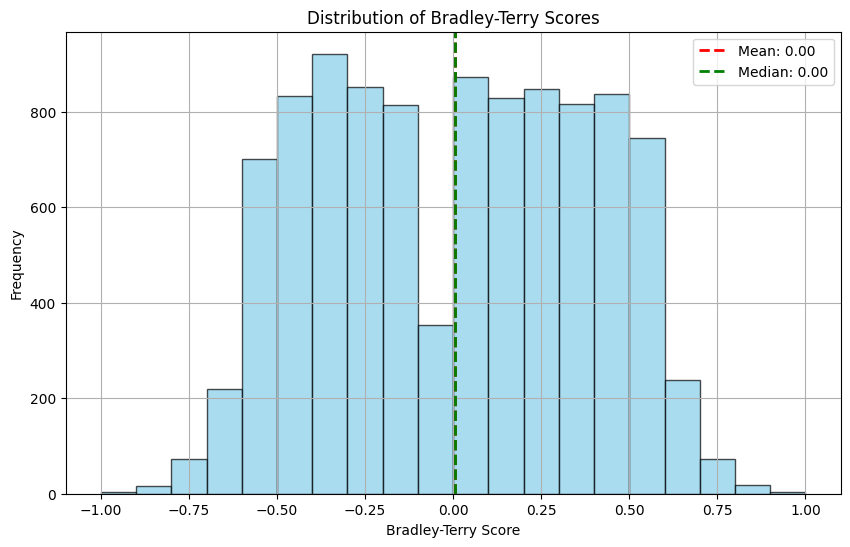

In [53]:
import matplotlib.pyplot as plt

# Plot the distribution
plt.figure(figsize=(10, 6))
emopair_aro_untied.scored_df['Bradley_Terry_Score'].hist(bins=20, alpha=0.7, color='skyblue', edgecolor='black')

# Calculate mean and median
mean_bt = emopair_aro_untied.scored_df['Bradley_Terry_Score'].mean()
median_bt = emopair_aro_untied.scored_df['Bradley_Terry_Score'].median()

# Add vertical lines for mean and median
plt.axvline(mean_bt, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_bt:.2f}')
plt.axvline(median_bt, color='green', linestyle='dashed', linewidth=2, label=f'Median: {median_bt:.2f}')

# Add labels and title
plt.title('Distribution of Bradley-Terry Scores')
plt.xlabel('Bradley-Terry Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

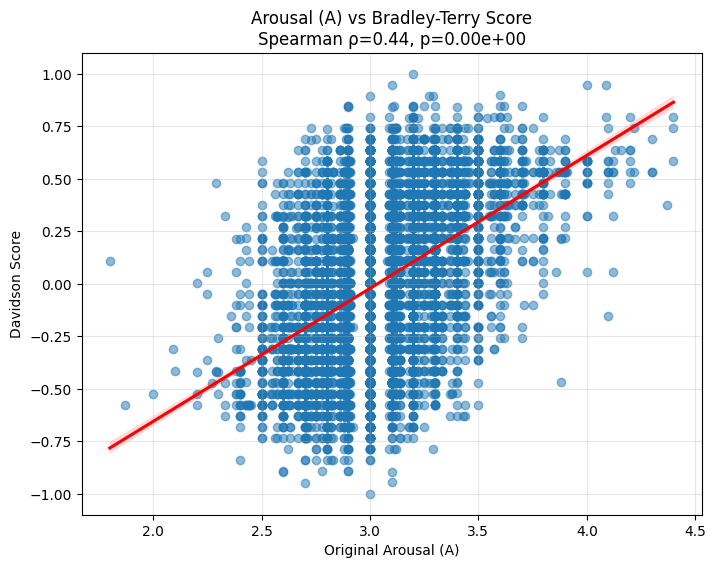

In [56]:
import seaborn as sns
from scipy import stats

# Calculate correlation statistics
r, p = stats.spearmanr(emopair_aro_untied.scored_df['A'], emopair_aro_untied.scored_df['Bradley_Terry_Score'])

# Create the plot
plt.figure(figsize=(8, 6))
sns.regplot(data=emopair_aro_untied.scored_df, x='A', y='Bradley_Terry_Score', 
            scatter_kws={'alpha':0.5}, line_kws={'color': 'red'})

# Add labels and title with stats
plt.title(f'Arousal (A) vs Bradley-Terry Score\nSpearman ρ={r:.2f}, p={p:.2e}')
plt.xlabel('Original Arousal (A)')
plt.ylabel('Davidson Score')
plt.grid(True, alpha=0.3)
plt.show()

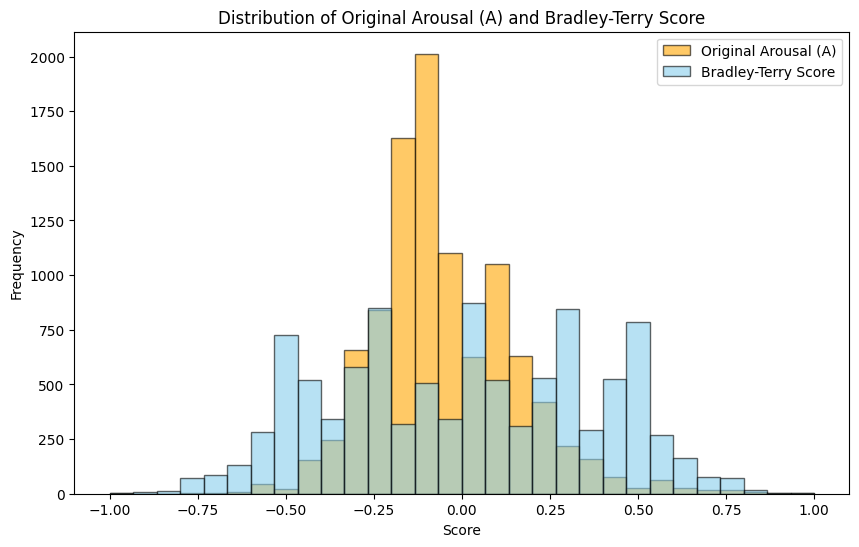

In [57]:
# Rescale 'A' from original (likely 1-5) to -1 to 1
A_min, A_max = emopair_aro_untied.scored_df['A'].min(), emopair_aro_untied.scored_df['A'].max()
emopair_aro_untied.scored_df['A_rescaled'] = 2 * (emopair_aro_untied.scored_df['A'] - A_min) / (A_max - A_min) - 1

plt.figure(figsize=(10, 6))

# Plot histogram for 'A'
plt.hist(emopair_aro_untied.scored_df['A_rescaled'], bins=30, alpha=0.6, color='orange', label='Original Arousal (A)', edgecolor='black')

# Plot histogram for 'Davidson_Score'
plt.hist(emopair_aro_untied.scored_df['Bradley_Terry_Score'], bins=30, alpha=0.6, color='skyblue', label='Bradley-Terry Score', edgecolor='black')

plt.title('Distribution of Original Arousal (A) and Bradley-Terry Score')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

## Dominance

In [64]:
emopair_dom_untied = pdm.Pairadigm(
    data = emobank, 
    item_id_name='id', 
    text_name='text',
    prior_breakdown_cols=['CGCOT_Breakdown'],
    cgcot_prompts=dom_prompts,
    model_name='claude-sonnet-4-5', 
    api_key=os.getenv('ANTHROPIC_API_KEY'),
    target_concept='dominance'
)


In [66]:
pdm.build_pairadigm(emopair_dom_untied, 
                    num_pairs_per_item=10, 
                    normalization_scale='negative-one-to-one')


STEP 1: GENERATING CGCOT BREAKDOWNS

Generating breakdowns for 10062 items using: claude-sonnet-4-5
[10062/10062] 100.0% complete
Completed: 10062/10062 items

Breakdowns added to [object name].data with column name(s): CGCoT_Breakdown
✓ Breakdowns generated successfully

STEP 2: GENERATING PAIRINGS
Pairwise DataFrame with breakdowns created and stored in self.pairwise_df
✓ Generated 58221 pairings

STEP 3: GENERATING PAIRWISE LLM ANNOTATIONS
[default] Completed 50/58221 comparisons
[default] Completed 100/58221 comparisons
[default] Completed 150/58221 comparisons
[default] Completed 200/58221 comparisons
[default] Completed 250/58221 comparisons
[default] Completed 300/58221 comparisons
[default] Completed 350/58221 comparisons
[default] Completed 400/58221 comparisons
[default] Completed 450/58221 comparisons
[default] Completed 500/58221 comparisons
[default] Completed 550/58221 comparisons
[default] Completed 600/58221 comparisons
[default] Completed 650/58221 comparisons
[defaul

{'breakdowns': None,
 'pairings':                               item1                         item2  \
 0         Homosexuality_12358_12505     Homosexuality_12457_12505   
 1      The_Black_Willow_11483_11570  lessig_blog-carbon_5617_5700   
 2        cable_spool_fort_8413_8465    cable_spool_fort_8516_8674   
 3      Nathans_Bylichka_57176_57235          defenders5_1090_1102   
 4      Nathans_Bylichka_12685_12703        anth_essay_4_7685_7776   
 ...                             ...                           ...   
 58216                   SemEval_602                 lw1_2561_2592   
 58217        Ohio_Steel_14047_14126            vampires_1126_1179   
 58218                   SemEval_871  hotel-california_29819_29868   
 58219             Ant_Robot_339_506  Nathans_Bylichka_14614_14634   
 58220                   SemEval_858    The_Black_Willow_9062_9213   
 
                                               breakdown1  \
 0      Original Text: Dobbens reasoned that most pare...   
 1 

### NEED TO REVIEW ERRORS

In [71]:
mask = emopair_dom_untied.pairwise_df['decision'] == 'ERROR'
emopair_dom_untied.pairwise_df[mask]

,item1,item2,breakdown1,breakdown2,decision,justification
2096,Fermentation_Eminent-Domain_11376_11484,blog-monastery_5375_5427,"Original Text: sorry, I keep forgetting the Fe...",Original Text: This weekend reminded me that I...,ERROR,list index out of range
3363,119CWL041_18_32,Fermentation_Eminent-Domain_11376_11484,"Original Text: March 29, 1999\nPrompt 1 respon...","Original Text: sorry, I keep forgetting the Fe...",ERROR,list index out of range
3545,Fermentation_Eminent-Domain_11376_11484,hotel-california_23970_23991,"Original Text: sorry, I keep forgetting the Fe...",Original Text: “Of course we notice.\nPrompt 1...,ERROR,list index out of range
4020,110CYL200_947_1076,easy_money_2368_2516,"Original Text: Unemployed, homeless and with a...","Original Text: I'm a researcher, I've come int...",ERROR,list index out of range
4270,A_defense_of_Michael_Moore_6101_6239,audubon1_2448_2609,Original Text: This is plausible -- but entire...,Original Text: Because the USDA’s slow-acting ...,ERROR,list index out of range
...,...,...,...,...,...,...
54721,Fermentation_Eminent-Domain_11376_11484,SemEval_978,"Original Text: sorry, I keep forgetting the Fe...",Original Text: No e-Book for Harry Potter VII\...,ERROR,list index out of range
54872,117CWL008_1449_1499,Nathans_Bylichka_27479_27562,Original Text: Thank you in advance for your c...,Original Text: It’s been in our collection for...,ERROR,list index out of range
55694,119CWL041_222_312,audubon1_132_395,Original Text: We must be able to reach all yo...,Original Text: Just imagine finding your favor...,ERROR,list index out of range
56438,Nathans_Bylichka_34187_34243,wildelifewatch1_1094_1237,Original Text: “A little walking should get th...,Original Text: But I also hope you will help u...,ERROR,list index out of range


In [77]:
emopair_dom_untied.score_items(normalization_scale='negative-one-to-one')

/Users/mlchrzan/opt/anaconda3/envs/emopair/lib/python3.12/site-packages/pairadigm/core.py:3146: UserWarning:

Some rows filtered out due to invalid decision values. Using 58158/58221 comparisons.



[default] Bradley-Terry model fitted with 58158 comparisons
[default] Mean dominance score: 0.077
[default] Std dominance score: 0.336
Score range: -1.000 to 1.000
25th percentile: -0.216
50th percentile (median): 0.078
75th percentile: 0.370

Highest scoring item on dominance (score: 1.000):
Apparently the drug use, sexual excess, and weird UCI experiences haven't softened your brain yet.

Lowest scoring item on dominance (score: -1.000):
“But …but sir,”
mean: 0.077
median: 0.078
std: 0.336
min: -1.000
max: 1.000
count: 10062.000


,id,split,V,A,D,text,CGCoT_Breakdown,Bradley_Terry_Score
0,110CYL068_1036_1079,train,3.00,3.00,3.20,"Remember what she said in my last letter? """,Original Text: Remember what she said in my la...,-0.314040
1,110CYL068_1079_1110,test,2.80,3.10,2.80,If I wasn't working here.,Original Text: If I wasn't working here.\nProm...,-0.313774
2,110CYL068_1127_1130,train,3.00,3.00,3.00,"..""","Original Text: ..""\nPrompt 1 response: I'd be ...",-0.411762
3,110CYL068_1137_1188,train,3.44,3.00,3.22,Goodwill helps people get off of public assist...,Original Text: Goodwill helps people get off o...,0.758803
4,110CYL068_1189_1328,train,3.55,3.27,3.46,Sherry learned through our Future Works class ...,Original Text: Sherry learned through our Futu...,0.273397
...,...,...,...,...,...,...,...,...
10057,wwf12_4531_4624,train,3.00,3.50,3.00,Please let it be a constant reminder of all yo...,Original Text: Please let it be a constant rem...,-0.167124
10058,wwf12_501_591,train,3.80,3.40,3.60,That’s why I want to extend my appreciation fo...,Original Text: That’s why I want to extend my ...,-0.118160
10059,wwf12_592_691,train,3.00,3.00,3.10,And why I’m writing you today to ask you to re...,Original Text: And why I’m writing you today t...,-0.166372
10060,wwf12_702_921,train,3.33,3.44,3.44,"In fact, I want to urge you to strengthen your...","Original Text: In fact, I want to urge you to ...",0.419108


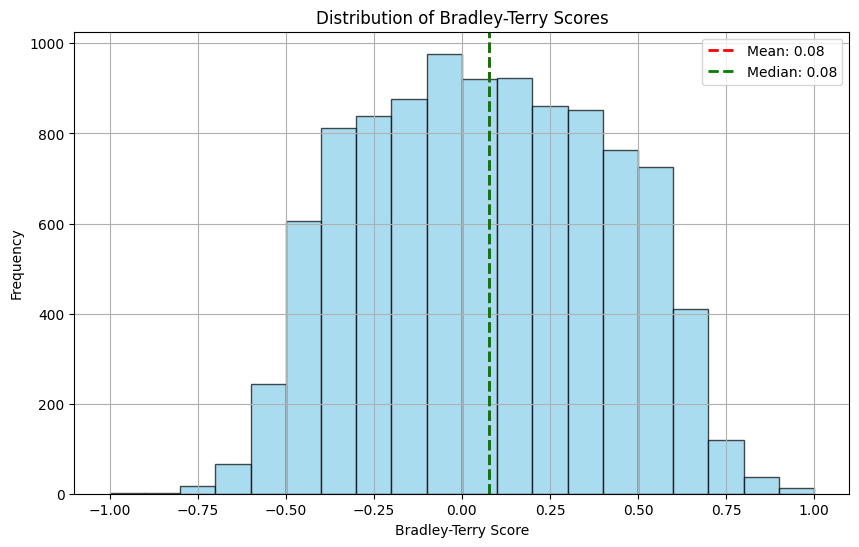

In [79]:
import matplotlib.pyplot as plt

# Plot the distribution
plt.figure(figsize=(10, 6))
emopair_dom_untied.scored_df['Bradley_Terry_Score'].hist(bins=20, alpha=0.7, color='skyblue', edgecolor='black')

# Calculate mean and median
mean_bt = emopair_dom_untied.scored_df['Bradley_Terry_Score'].mean()
median_bt = emopair_dom_untied.scored_df['Bradley_Terry_Score'].median()
# Add vertical lines for mean and median
plt.axvline(mean_bt, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_bt:.2f}')
plt.axvline(median_bt, color='green', linestyle='dashed', linewidth=2, label=f'Median: {median_bt:.2f}')

# Add labels and title
plt.title('Distribution of Bradley-Terry Scores')
plt.xlabel('Bradley-Terry Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

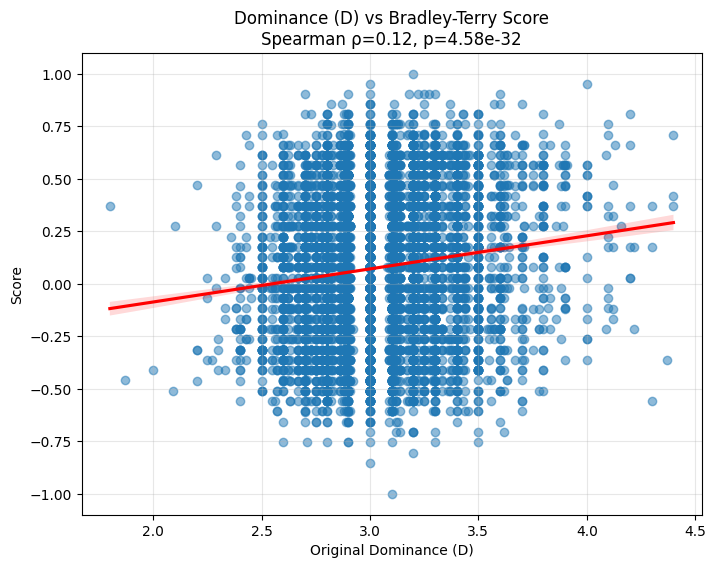

In [80]:
import seaborn as sns
from scipy import stats

# Calculate correlation statistics
r, p = stats.spearmanr(emopair_dom_untied.scored_df['A'], emopair_dom_untied.scored_df['Bradley_Terry_Score'])

# Create the plot
plt.figure(figsize=(8, 6))
sns.regplot(data=emopair_dom_untied.scored_df, x='A', y='Bradley_Terry_Score', 
            scatter_kws={'alpha':0.5}, line_kws={'color': 'red'})

# Add labels and title with stats
plt.title(f'Dominance (D) vs Bradley-Terry Score\nSpearman ρ={r:.2f}, p={p:.2e}')
plt.xlabel('Original Dominance (D)')
plt.ylabel('Score')
plt.grid(True, alpha=0.3)
plt.show()

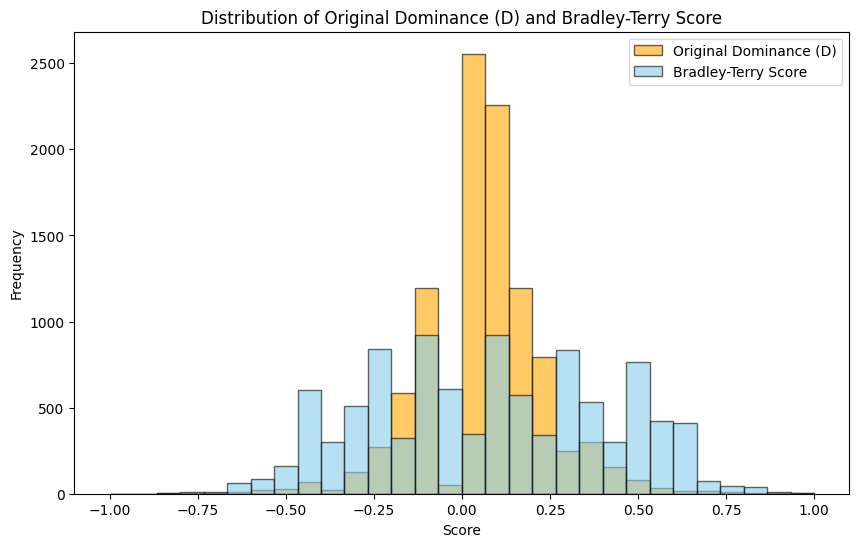

In [95]:
# Rescale 'A' from original (likely 1-5) to -1 to 1
D_min, D_max = emopair_dom_untied.scored_df['D'].min(), emopair_dom_untied.scored_df['D'].max()
emopair_dom_untied.scored_df['D_rescaled'] = 2 * (emopair_dom_untied.scored_df['D'] - D_min) / (D_max - D_min) - 1

plt.figure(figsize=(10, 6))

# Plot histogram for 'A'
plt.hist(emopair_dom_untied.scored_df['D_rescaled'], bins=30, alpha=0.6, color='orange', label='Original Dominance (D)', edgecolor='black')

# Plot histogram for 'Davidson_Score'
plt.hist(emopair_dom_untied.scored_df['Bradley_Terry_Score'], bins=30, alpha=0.6, color='skyblue', label='Bradley-Terry Score', edgecolor='black')

plt.title('Distribution of Original Dominance (D) and Bradley-Terry Score')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [ ]:
# Save Local
emopair_dom_untied.save('Results/pairadigms/emopair_dom_untied')
emopair_dom_untied.pairwise_df.to_csv('Results/emopair_dom_untied_pairwise_annotations.csv', index=False)
emopair_dom_untied.scored_df.to_csv('Results/emopair_dom_untied_scores.csv', index=False)

# Save to Box
emopair_dom_untied.save('/Users/mlchrzan/Library/CloudStorage/Box-Box/emopair_dom_untied')
emopair_dom_untied.pairwise_df.to_csv('/Users/mlchrzan/Library/CloudStorage/Box-Box/emopair_dom_untied_pairwise_annotations.csv', index=False)
emopair_dom_untied.scored_df.to_csv('/Users/mlchrzan/Library/CloudStorage/Box-Box/emopair_dom_untied_scores.csv', index=False)

Pairadigm object saved successfully to: Results/pairadigms/emopair_dom_untied.pkl
Pairadigm object saved successfully to: /Users/mlchrzan/Library/CloudStorage/Box-Box/emopair_dom_untied.pkl
